# Simulación numérica en física: integradores, Monte Carlo y difusión

Notebook de métodos numéricos implementados **desde cero** con NumPy (sin `scipy.integrate`), para entender qué hace cada método, cuánto se equivoca y por qué.

1. Oscilador armónico: Euler vs Runge-Kutta 4 y conservación de la energía
2. Orden de convergencia medido numéricamente
3. Proyectil con rozamiento del aire: ¿sigue siendo 45° el mejor ángulo?
4. Monte Carlo: estimar π y el error que cae como 1/√N
5. Caminatas aleatorias: difusión y desplazamiento cuadrático medio

In [1]:
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src import integradores as it, montecarlo as mc
from src.estilo import aplicar_estilo, AZUL, NARANJA, AQUA, AMARILLO, TEXTO_SEC
aplicar_estilo()
FIG = "../figuras/"

## 1. Oscilador armónico: el método importa

Ecuación $\ddot x = -\omega^2 x$. La energía $E = \tfrac12 v^2 + \tfrac12 \omega^2 x^2$ debería mantenerse constante.
Integramos 20 períodos con el **mismo paso** $h = 0{,}05$ usando Euler y RK4.

Euler           energía final / inicial = 530.945797
Runge-Kutta 4   energía final / inicial = 0.999999


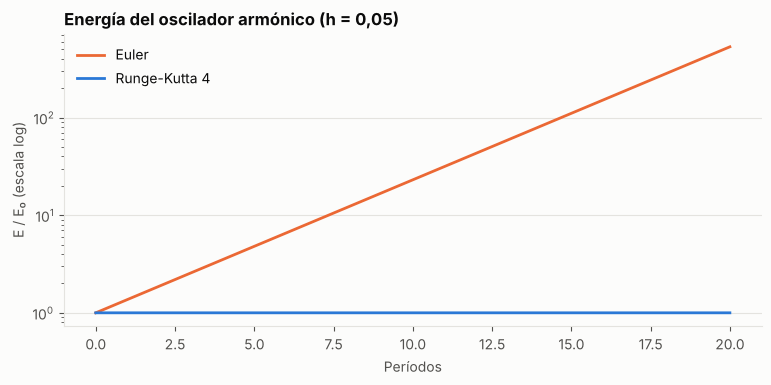

In [2]:
h, T = 0.05, 20 * 2 * np.pi
f = it.oscilador_armonico(omega=1.0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for metodo, color, nombre in [("euler", NARANJA, "Euler"), ("rk4", AZUL, "Runge-Kutta 4")]:
    t, y = it.integrar(f, [1.0, 0.0], 0.0, T, h, metodo)
    energia = 0.5 * y[:, 1]**2 + 0.5 * y[:, 0]**2
    ax.plot(t / (2 * np.pi), energia / energia[0], color=color, label=nombre)
    print(f"{nombre:15s} energía final / inicial = {energia[-1] / energia[0]:.6f}")
ax.set_xlabel("Períodos")
ax.set_yscale("log")
ax.set_ylabel("E / E₀ (escala log)")
ax.set_title("Energía del oscilador armónico (h = 0,05)")
ax.legend(loc="upper left")
fig.savefig(FIG + "01_energia_oscilador.png")

Con Euler la energía crece sin límite: cada paso la multiplica exactamente por $(1 + h^2)$, así que después de 20 períodos (unos 2500 pasos) el oscilador tiene **unas 530 veces la energía inicial**. Es un resultado físicamente imposible que viene solo del método. RK4, con el mismo paso, conserva la energía hasta la sexta cifra.

## 2. Orden de convergencia

Si el error global es $\varepsilon \propto h^p$, en escala log-log se ve una recta de pendiente $p$. Medimos el error en $t = 5$ contra la solución exacta $x = \cos t$.

Orden medido: Euler = 1.05   RK4 = 4.00


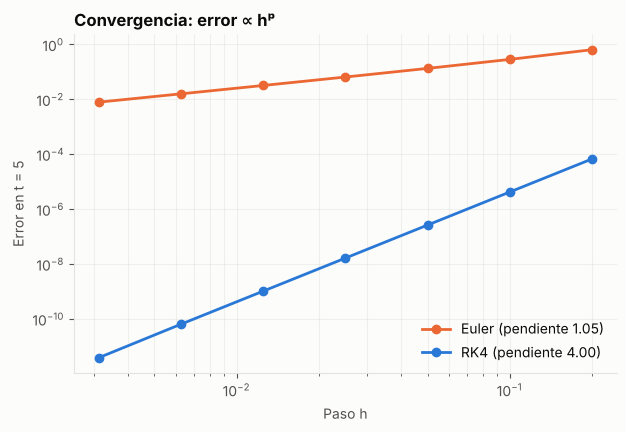

In [3]:
def error(metodo, h):
    t, y = it.integrar(f, [1.0, 0.0], 0.0, 5.0, h, metodo)
    return np.hypot(y[-1, 0] - np.cos(t[-1]), y[-1, 1] + np.sin(t[-1]))

hs = 5.0 / np.array([25, 50, 100, 200, 400, 800, 1600])
err_euler = np.array([error("euler", h) for h in hs])
err_rk4 = np.array([error("rk4", h) for h in hs])
p_euler = it.orden_convergencia(hs, err_euler)
p_rk4 = it.orden_convergencia(hs[:5], err_rk4[:5])   # los pasos más chicos ya tocan el redondeo de máquina
print(f"Orden medido: Euler = {p_euler:.2f}   RK4 = {p_rk4:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.loglog(hs, err_euler, "o-", color=NARANJA, label=f"Euler (pendiente {p_euler:.2f})")
ax.loglog(hs, err_rk4, "o-", color=AZUL, label=f"RK4 (pendiente {p_rk4:.2f})")
ax.set_xlabel("Paso h")
ax.set_ylabel("Error en t = 5")
ax.set_title("Convergencia: error ∝ hᵖ")
ax.grid(True, which="both", axis="both", alpha=0.5)
ax.legend(loc="lower right")
fig.savefig(FIG + "02_convergencia.png")

Las pendientes medidas coinciden con la teoría: **1 para Euler y 4 para RK4**. En la práctica: dividir el paso por 2 reduce el error de RK4 unas 16 veces, y el de Euler solo 2. Para llegar a un error de $10^{-6}$ en este problema, RK4 necesita menos de 100 pasos y Euler, más de 10 millones.

## 3. Proyectil con rozamiento del aire

Con rozamiento cuadrático $\vec a = -g\,\hat z - k\,|\vec v|\,\vec v$ no hay solución analítica, así que hay que integrar.
$k = \rho C_d A / 2m$; para una pelota de fútbol $k \approx 0{,}01\ \text{m}^{-1}$.

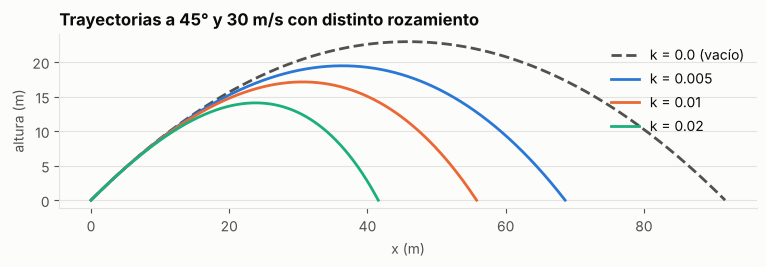

In [4]:
v0, ang = 30.0, 45.0
fig, ax = plt.subplots(figsize=(9, 4))
for k, color in zip([0.0, 0.005, 0.01, 0.02], [TEXTO_SEC, AZUL, NARANJA, AQUA]):
    a = np.radians(ang)
    t, y = it.integrar(it.proyectil(k=k), [0, 0, v0 * np.cos(a), v0 * np.sin(a)], 0, 20, 1e-3, "rk4",
                       detener=lambda s: s[1] < 0)
    ax.plot(y[:, 0], np.maximum(y[:, 1], 0), color=color, ls="--" if k == 0 else "-",
            label=f"k = {k}" + (" (vacío)" if k == 0 else ""))
ax.set_xlabel("x (m)"); ax.set_ylabel("altura (m)")
ax.set_title("Trayectorias a 45° y 30 m/s con distinto rozamiento")
ax.set_aspect("equal"); ax.legend(loc="upper right")
fig.savefig(FIG + "03_trayectorias.png")

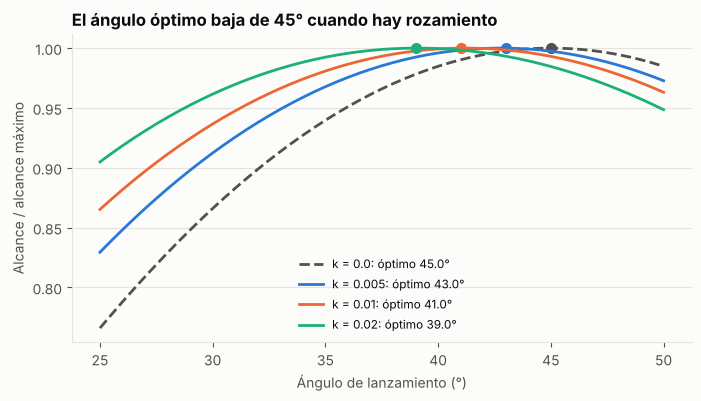

In [5]:
angulos = np.arange(25, 50.5, 0.5)
fig, ax = plt.subplots(figsize=(8, 4))
for k, color in zip([0.0, 0.005, 0.01, 0.02], [TEXTO_SEC, AZUL, NARANJA, AQUA]):
    alc = np.array([it.alcance(v0, a, k, h=2e-3) for a in angulos])
    mejor = angulos[alc.argmax()]
    ax.plot(angulos, alc / alc.max(), color=color, ls="--" if k == 0 else "-", label=f"k = {k}: óptimo {mejor:.1f}°")
    ax.plot(mejor, 1, "o", color=color, ms=7)
ax.set_xlabel("Ángulo de lanzamiento (°)"); ax.set_ylabel("Alcance / alcance máximo")
ax.set_title("El ángulo óptimo baja de 45° cuando hay rozamiento")
ax.legend(loc="lower center", fontsize=8.5)
fig.savefig(FIG + "04_angulo_optimo.png")

El famoso 45° solo vale en el vacío. Con rozamiento, una trayectoria alta pasa más tiempo en el aire perdiendo velocidad, así que **conviene lanzar más bajo**. Con $k = 0{,}01$ (una pelota de fútbol a 30 m/s) el óptimo es 41° y el alcance cae de 92 m a 56 m; con $k = 0{,}02$ el óptimo baja a 39°.

## 4. Monte Carlo: estimar π

Se tiran $N$ puntos al azar en el cuadrado $[-1, 1]^2$. La fracción que cae dentro del círculo unitario tiende a $\pi/4$.
El error estándar es $4\sqrt{p(1-p)/N}$: cae como $1/\sqrt{N}$, **sin importar la dimensión del problema**. Por eso Monte Carlo es la herramienta estándar para integrales en muchas dimensiones.

Con 10 millones de puntos: π ≈ 3.14189 ± 0.00052


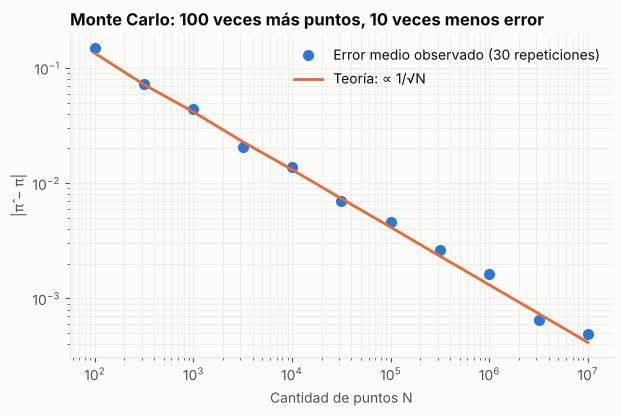

In [6]:
rng = np.random.default_rng(42)
Ns = np.logspace(2, 7, 11).astype(int)
repeticiones = 30
err_real = [np.mean([abs(mc.estimar_pi(n, rng)[0] - np.pi) for _ in range(repeticiones)]) for n in Ns]
err_teo = [mc.estimar_pi(n, rng)[1] * np.sqrt(2 / np.pi) for n in Ns]   # E|Z| = σ·√(2/π)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(Ns, err_real, "o", color=AZUL, ms=7, label=f"Error medio observado ({repeticiones} repeticiones)")
ax.loglog(Ns, err_teo, "-", color=NARANJA, label="Teoría: ∝ 1/√N")
ax.set_xlabel("Cantidad de puntos N"); ax.set_ylabel("|π̂ − π|")
ax.set_title("Monte Carlo: 100 veces más puntos, 10 veces menos error")
ax.grid(True, which="both", axis="both", alpha=0.5); ax.legend(loc="upper right")
fig.savefig(FIG + "05_montecarlo_pi.png")
est, sd = mc.estimar_pi(10_000_000, rng)
print(f"Con 10 millones de puntos: π ≈ {est:.5f} ± {sd:.5f}")

## 5. Caminatas aleatorias y difusión

Cada partícula da pasos de largo 1 en una dirección al azar. Ninguna trayectoria es predecible, pero el promedio sí: el **desplazamiento cuadrático medio crece linealmente con el tiempo**, $\langle r^2 \rangle = n\,a^2 = 4Dt$. Es la firma de la difusión (Einstein, 1905) y la base del movimiento browniano.

Pendiente de <r²> vs pasos: 1.014  (teoría: 1, D = a²/4 = 0,25 por paso)


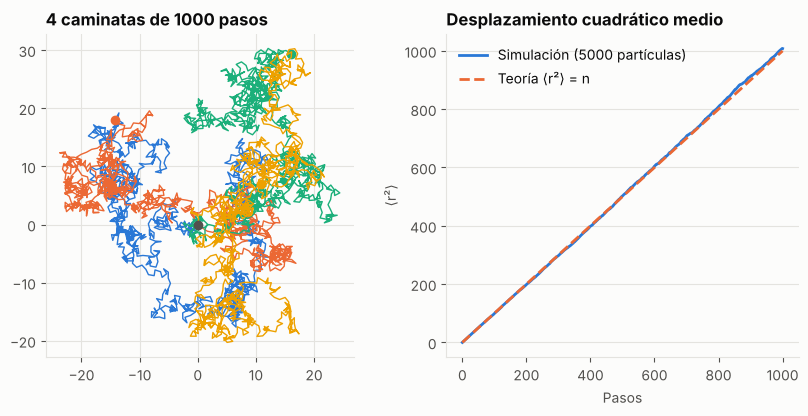

In [7]:
rng = np.random.default_rng(7)
pos = mc.caminatas_2d(n_pasos=1000, n_caminantes=5000, rng=rng)
msd = mc.desplazamiento_cuadratico_medio(pos)
pendiente = np.polyfit(np.arange(len(msd)), msd, 1)[0]
print(f"Pendiente de <r²> vs pasos: {pendiente:.3f}  (teoría: 1, D = a²/4 = 0,25 por paso)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
for i, c in enumerate([AZUL, NARANJA, AQUA, AMARILLO]):
    a1.plot(pos[:, i, 0], pos[:, i, 1], color=c, lw=1)
    a1.plot(pos[-1, i, 0], pos[-1, i, 1], "o", color=c, ms=6)
a1.plot(0, 0, "o", color=TEXTO_SEC, ms=6)
a1.set_aspect("equal"); a1.set_title("4 caminatas de 1000 pasos"); a1.grid(True, axis="both")
a2.plot(msd, color=AZUL, label="Simulación (5000 partículas)")
a2.plot(np.arange(len(msd)), np.arange(len(msd)), "--", color=NARANJA, label="Teoría ⟨r²⟩ = n")
a2.set_xlabel("Pasos"); a2.set_ylabel("⟨r²⟩"); a2.set_title("Desplazamiento cuadrático medio")
a2.legend(loc="upper left")
fig.savefig(FIG + "06_difusion.png")

## Qué muestra este notebook

- Implementar un método y **medir** su error, en lugar de confiar en una librería como caja negra.
- Validar contra soluciones exactas y teoría antes de usar el método en un problema sin solución conocida (el proyectil con rozamiento).
- Razonar estadísticamente sobre la incertidumbre de una simulación (error ∝ 1/√N).

Son las mismas herramientas que uso en análisis de datos: validación, cuantificación del error y simulación de escenarios.